In [1]:
# matplolib 한글 설정

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Noto Sans CJK KR'
plt.rcParams['axes.unicode_minus'] = False

# 2. 머신러닝 프로젝트 처음부터 끝까지

## 2.1 실제 데이터로 작업하기

- 참고할 공개 데이터 저장소들
    - 구글 데이터셋 검색
    - 허길페이스 데이터셋
    - OpenML.org
    - 캐글
    - UC 언바인 머신러닝 저장소
    - 스탠퍼드 대규모 네트워크 데이터셋 컬랙션
    - US 정부 오픈 데이터
    - 데이터 포털
    - 위키백과 머신러닝 데이터셋 목록

## 2.2 큰 그림 보기

- 사용할 실습 시나리오 : 캘리포니아 인구 조사 데이터 -> 주택 가격 모델 만들기
    - 인구 블록(단위) 마다 : 인구, 중위 소득, 중위 주택 가격 등을 예측하기

### 2.2.1 문제정의

1) '문제 상황이 무엇인가? 내가/우리 팀이 무엇을 해결하면 되나?'를 잘 질문하자
    - 시나리오 상황 : 지역에 대해 투자 가치 평가 모델을 구성중. 이 모델은 구역 가격을 예측하고 다른 모델의 또 다른 입력으로 활용될 예정
    - 파이프라인 : 데이터 처리 컴포넌트들이 연속되 있는 것을 데이터 파이프라인이라고 한다.
        - 컴포넌트 -> 비동기적 작동
        - 각 컴포넌트 -> 완전히 서로 독립적 : 즉, 컴포넌트 사이 인터페이스 = 데이터 저장소 뿐
2) '현재(or 과거) 솔루션은 어땠는가?' : 문제 해결에 대한 정보 + 참고 상황
3) 시스템(or 아키텍처) 설계 준비 : 레이블 데셋 -> 회귀(지도학습) ; 여러 feat 변수 입력 통해 단일 target 변수 예측 -> 다중-단변량 회귀(반대로 여러 입력 변수 -> 여러 target 변수 예측 : 다중-다변량 회귀)

### 2.2.3 성능 측정 지표 선택

- 평균 제곱근 오차 : 회귀 문제의 대표적인 성능 지표
    - $RMSE(X,y,h) = \sqrt{\frac{1}{m}\sum_{i=1}^m (h(x^{(i)})-y^{(i)})^2} = \sqrt{\cdots (y_i - \hat{y}_i)^2}$

- ML에서의 표기법/notation
    - $m$ : 입력 데셋의 샘플 수 ; ex) $\dim(X_{row}) = m; \quad i \in [1,m]$
    - $X$ : 모든 샘플의 feat.가 담긴 input mat. ; row -> 각 샘플 케이스, colunm -> 각 feat.
        - ex) $X = \begin{pmatrix} x'_1 \\ \vdots \\ x'_{67} \\ \vdots \\ x'_m \end{pmatrix} = \begin{pmatrix} &\vdots& \\ 123.45 & -14.14 & 3.14 \\ &\vdots& \end{pmatrix}$
            - (let $x^{(i)} = x_i, (x)^{\top} = x^T = x'$)
        - $x^{(i)}$ : i번째 샘플의 feat. vec. ; ex) $x^{(67)} = \begin{pmatrix} 123.45 \\ -14.14 \\ 3.14 \end{pmatrix}$
    - $y$ : 모든 샘플의 레이블이 담긴 target vec.
        - $y^{(i)}$ : i번째 샘플의 레이블(or target) ; ex) $y^{(67)} = 271828.3141$
    - $h,\hat{y}^{(i)}$ : 모델의 예측함수, 가설. 모델이 $x^{(i)}$ 입력 -> $h(x^{(i)})=\hat{y}^{(i)}$ 출력함. 
    - $\epsilon, e$ : 
        - $\epsilon$(오차) : 모집단의 참모델이 가지는 참값과 실제 종속변수 값간 차이(실제론 관측 X)
        - $e$(잔차) : 표본에 대한 예측모델의 예측값과 관측값 간 차이 (관측 및 계산 O)
        - $y_i=f_{\text{true}}(x_i)+\epsilon_i,\quad \hat{y}_i=f_{\text{pred.}}(x_i)\implies e_i=y_i-\hat{y}_i$
    - $RMSE(X,y,h)$ : 가설 h를 사용해 샘플을 평가하는 cost func. (or Loss func)

- MAE(평균 절대 오차) : 상황에 따라 고려할 추가 loss func.
    - 데이터 이상치 $\uparrow$? $\to$ RMSE 이상치 민감. (단, outlier $\downarrow$ $\to$ RMSE good )
    - $MAE(X,y,h) = \frac{1}{m} \sum_{i=1}^m |y^{(i)}-h(x^{(i)})|$
    - norm(노름) : RMSE, MAE 모두 타깃과 예측간 거리를 잼. 거리 측정에 여러 노름들 고려 가능
        - L2/$l_2$ norm(유클리드 노름/거리) : ($||\cdot||$ or) $||\cdot||_2 = \sqrt{x_1^2+\cdots+x_n^2}$   
        - L1/$l_1$ norm(맨해튼 노름) : $||\cdot||_1 = ({|x_1|+\cdots+|x_n|})$
        - $l_k$ norm (일반화): $||\vec{x}||_k = \sqrt[k]{|x_1|^k+\cdots+|x_n|^k}$
            - $l_0, l_\infty$ norm : $l_0 \to n(\forall x|x\neq 0),\quad l_\infty \to \max{(|x_1|,\cdots,|x_n|)}$

- (참고) 통계학/ML 간 용어 차이 정리 (출처 : All of statistics, Preface xi)
    - (주석) : 원문이 2003년 출판이므로 현재의 정의와 지식과는 다를 수 있음

|통계학|ML(CS)|의미|
|---|---|---|
|estimation(추정)|learning(학습)|데이터를 사용해 미지의 값를 예측|
|classification(분류)|supervised learning(지도학습)|X로부터 이산적인 Y를 예측|
|clustering data(데이터 군집화)|unsupervised learning(비지도학습)|데이터를 그룹으로 묶음|
|data|trainging sample|$(X_1,Y_1),\cdots,(X_n,Y_n)$|
|covariates(공변량)|features|$X'_i$ 들|
|classifier(분류기)|hypothesis|공변량에서 결과값까지의 사상(매핑)|
|hypothesis|"|모수공간 $\Theta$의 부분집합|
|confidence interval(신뢰구간)|"|주어진 빈도 내에서 미지의 값을 포한하는 구간|
|directed acyclic graph(DAG; 유향비순환그래프)|Bayes net|주어진 조건부 독립 관계의 다변량 분포|
|Bayesian inference(베이지안 추론)|"|데이터를 사용해 믿음을 갱신하는 통계적 방법|
|frequentist inference(빈도주의 추론)|"|보장된 빈도적 양상에 대한 통계적 방법|
|large deviation bounds(대규모 편차 경계)|PAC learning|오차의 확률에 대한 균등 경계|

## 2.3 데이터 가져오기

### 2.3.3 인터랩티브한 환경의 편리함과 위험

- 주피터 노트북 : 각 셀을 순차적으로 실행하다가, 중간에 멈추고 새 셀을 추가한 다음 실행할 수 있고 또 다시 돌아가서 이전셀을 사용할 수 있다
    - 대신, 주피터 노트북을 다양하고 능동적으로 쓰는 대신 수동적으로 셀을 순서대로 사용하면 빨리 배울 수 없다.

### 2.3.5 데이터 다운로드

In [2]:
import tarfile
import urllib.request
from pathlib import Path

import pandas as pd


def load_housing_data() :
    tar_path = Path('datasets/housing.tgz')

    if not tar_path.is_file() : # tar_path 경로에 파일이 없다면
        url = 'https://github.com/ageron/data/raw/main/housing.tgz'

        Path('datasets').mkdir(parents=True, exist_ok=True) # 해당 경로 폴더 생성
        urllib.request.urlretrieve(url, tar_path) # url 링크에서 해당 경로로 .tgz 압축 파일 다운
        
        with tarfile.open(tar_path) as housing_tar :
            housing_tar.extractall(path='datasets', filter='data') # datasets 경로에 압축 풀기

    return pd.read_csv(Path('datasets/housing/housing.csv')) # 해당 경로에서 csv 파일 불러오기

housing_full = load_housing_data()

### 2.3.6 데이터 구조 둘러보기

#### 기본 판다스 데이터프레임 조작

- (ex : DF_name, col_name 가정)

- `DF_name.head()` : 첫 5개 row/샘플 출력
- `DF_name.info()` : 데이터에 관한 간단한 정보 (샘플 수, feat.들, feat.의 데이터 타입)
- `DF_name.['cat_col'].value_counts()` : (범주형 자료)'cat_col' 컬럼의 카테고리 종류와 갯수를 확인
- `DF_name.describe()` : 수치형 특성의 요약 정보
    - null값은 제외하고 셈

In [3]:
housing_full.head() 
# 첫 5개 row/샘플 출력

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
# 데이터에 관한 간단한 정보 (샘플 수, feat.들, feat.의 데이터 타입)
housing_full.info() 

# total_bedrooms : 총 20640개중 20433만 O. 결측치 O
# ocean_proximity : 유일하게 수치형 X. str 타입(범주형일 가능성)

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
# ocean_proximity에 카테고리 종류, 각 카테고리의 갯수를 확인
housing_full['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [6]:
# 수치형 특성의 요약 정보
housing_full.describe()

# null은 빼고 센다
# std : 표준 편차
# 25%, 50%, 75% : 해당 백분위수

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


#### 기본 matplotlib의 pyplot 조작 (히스토그램)

- `import matplotlib.pyplot as plt` : 임포트
- `DF_name.hist(bins=xxx, figsize=(yyy,zzz))` : 히스토그램 기본 선언
    - bins로 값 범위 갯수 조정
- `plt.show()` : 그래프 출력

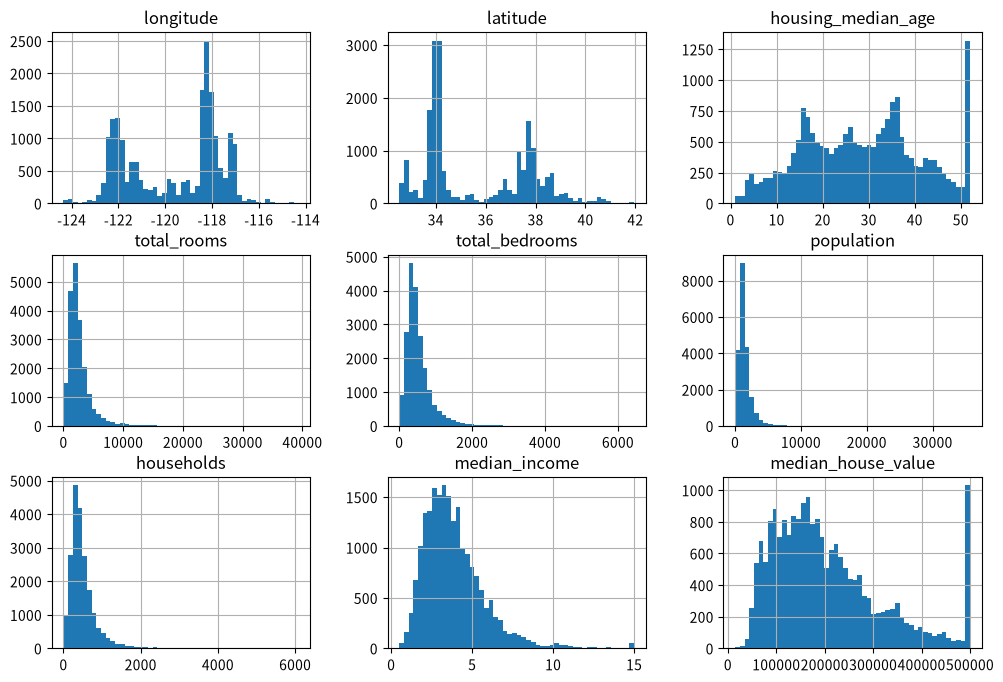

In [7]:
# 히스토그램 출력
# 값 범위 개수는 bins 파라미터로 조절 가능

import matplotlib.pyplot as plt

housing_full.hist(bins=50, figsize=(12,8))

plt.show()

#### 주택 데셋 히스토그램에서 확인 가능한 사항

1) 중위소득 : US 달러 표시 X; [0.5, 15] 구간으로 변경. 1 = 10,000 US\$
    - 전처리된 데이터가 어떤 계산을 통해 얻었는지 아는게 중요
2) 중위 주택 연식, 중위 주택 가격: 최댓값, 최솟값을 지정함. 특히 housing_median_value는 타깃(y값)이므로 조심해야함. 50만달러를 초과하는 예측값이 필요할 경우 다음의 선택지 고려
    1) 범위 밖 구간에 대한 정확한 레이블 구하기
    2) 훈련세트에서 해당 구역 제거
        - ( \> 50만 달러 샘플) -> 이상치, 일반화 hard
3) feat. 들의 스케일이 서로 많이 다름. 정규화 필요
4) 상당수 히스토그램 분포에서 우측 꼬리가 더 김 -> 다수 ML 알고리즘 학습 hard.


### 2.3.7 테스트 세트 만들기

- 훈련세트중 테스트 세트를 분리; 테스트셋에서 자의적으로 패턴을 해석하면 X. 특정 ML모델을 임의로 선정할 수 O
- 데이터 스누핑 : 테스트셋을 임의적으로 해석하고 오차 추정시 매우 낙관적인 추정 -> 실제 런타임에서 기대 성능 X 일수도 

#### 단순한 완전 랜덤 샘플링

- 과정
    1) 데셋, 테셋비율을 입력받음
    2) 실제 테스트셋 크기 계산 : (테스트셋 크기) = (전체 데셋) * (테스트 비율)
    3) 데셋 크기만큼 0부터 할당된 정수 리스트의 순서를 섞음
    4) 3)의 리스트에서 테스트셋 크기만큼 앞쪽 리스트 잘라냄. 나머지는 훈련셋 지정
    5) 4)에서 지정한 각각 2개의 데이터 프레임 반환

- 시드값 고정

In [8]:
import numpy as np

# 간단히 보자면 테셋 생성은 전체 데이터의 20% 정도를 랜덤 샘플 추출 

def shuffle_and_split_data(data: pd.DataFrame, 
                           test_ratio : float, 
                           rng : any) -> pd.DataFrame :

    test_set_size = int(len(data) * test_ratio) # 테셋 비율만큼 실제 테셋 크기 계산 ex) test_set_size = 2000 
    shuffled_indices = rng.permutation(len(data)) # ex) len(data) = 10000 이면, [42, ..., 0, ..., 9999, ..., 67]로 섞음
    
    test_indices = shuffled_indices[ :test_set_size] # 테셋 크기만큼 뒤섞은 인덱스 자르기 ex) [:2000] : 0~1999 -> 테셋
    train_indices = shuffled_indices[test_set_size: ] # 나머지는 훈셋 할당

    return data.iloc[train_indices], data.iloc[test_indices] # 훈셋, 테셋을 분리한 판다스 데이터프레임 반환

    rng = np.random.default_rng(seed=42) # 결과값을 재현하기 위해 시드 지정

    

#### 해시값을 사용해 랜덤 샘플링

- 단순 랜덤 샘플링 문제점
    - 프로그램 재실행시 또 다른 테셋 생성 -> 여러번 반복시 ML 모델이 전체 데셋을 입력받을 수 있음
    1) 첫 실행에서 테셋 저장 후 다음 실행에서 불러오기
    2) 모든 난수 생성기의 시드값을 고정

- 데셋 업데이트시 문제점
    - 단, 두 방법 모두 이후 업데이트된 데셋을 사용시 문제됨. 따라서 해결책 3 추천  
 
    3) 파이썬 hash() 함수를 사용해 샘플 식별자로 데셋으로 보낼지 결정
        - 샘플당 식별자의 해시값 계산 -> 해시 최댓값의 20%보다 작거나 같은 샘플만 테셋으로 보낼 수 있음
        - (업뎃 후 새 테셋) = (업뎃 전 테셋) + (새 샘플의 20%) 프로그램 재실행시 또 다른 테셋 생성 -> 여러번 반복시 ML 모델이 전체 데셋을 입력받을 수 있음


In [9]:
# hash() 사용해 해시값 기준 데이터셋 분리

from zlib import crc32


def is_id_in_test_set(identifier : any, test_ratio : float) -> bool :
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data : pd.DataFrame, test_ratio : float, id_column : any) -> pd.DataFrame :
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_ : is_id_in_test_set(id_, test_ratio))

    return data.iloc[~in_test_set], data.iloc[in_test_set]

# 주택 데셋에 식별자 컬럼이 없으므로 기존 인덱스를 ID로 지정

housing_with_id = housing_full.reset_index() # index col.이 포함된 DF 반환
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, 'index')
 

- 기존 row의 인덱스를 고유 식별자로 사용시 주의점
    1) 새 데이터는 데이터셋 끝에 추가되어야하고, 어떠한 row도 삭제 X
    2) 1)이 불가능할 땐 고유 식별자로 지정할 안전한 feat. 을 활용해야함 ((위도,경도) 라던가, 고객ID, 시간순 등)

In [10]:
housing_with_id2 = housing_with_id
housing_with_id2['id'] = housing_full['longitude'] * 1000 + housing_full['latitude']
train_set, test_set = split_data_with_id_hash(housing_with_id2, 0.2, 'id')

print(train_set.head(3))

   index  longitude  latitude  housing_median_age  total_rooms  \
0      0    -122.23     37.88                41.0        880.0   
1      1    -122.22     37.86                21.0       7099.0   
2      2    -122.24     37.85                52.0       1467.0   

   total_bedrooms  population  households  median_income  median_house_value  \
0           129.0       322.0       126.0         8.3252            452600.0   
1          1106.0      2401.0      1138.0         8.3014            358500.0   
2           190.0       496.0       177.0         7.2574            352100.0   

  ocean_proximity         id  
0        NEAR BAY -122192.12  
1        NEAR BAY -122182.14  
2        NEAR BAY -122202.15  


#### 사이킷런 `train_test_split()` 함수
- 사이킷런은 데셋을 여려 서브셋으로 나누는 내장 함수들 지원
- 여기서 가장 비슷한건 train_test_split() 함수지만, 특징이 더 있음
    1) 난수값 지정 가능한 random_state 파라미터
    2) row 갯수가 같은 여러 데셋을 넘겨서 동일 인덱스 기준으로 나눌 수 있음 (DF가 레이블 따라 여러개로 나뉠때 유용)



In [11]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing_full, test_size=0.2, random_state=42)

test_set["total_bedrooms"].isnull().sum()
# 테셋의 total_bedrooms의 결측치를 세는 함수

np.int64(44)

#### 계층적 샘플링

- 순수 랜덤 샘플링이 괜찮은 상황
    - 데셋이 충분히 크다면 지금까지의 순수 랜덤 샘플링이 괜찮음
    - but, feat. 수에 비해 데셋이 부족? -> 샘플링 편향 O

- 계층적 샘플링
    - 모집단을 계층으로 나누고, 표본이 모집단을 대표하도록 각 계층에서 적절한 비율의 표본 추출
    - ex) 설문 기관에서 모집단의 성비가 남:여가 48.4:51.6이라면, 샘플 비율도 이를 유지해야함. 
    - 주택 예제의 중위 소득의 경우 : 꼬리가 긴 분포 O. 각 계층의 비율이 편향될 가능성
항
- 계층적 샘플링시 주의사항
    1) 계층별로 충분한 샘플 수 O : if x? -> 각 계층의 중요도에 대한 편향 O
    2) 너무 많은 계층으로 나눠선 X.
- `pd.cut()` : 각 계층을 범주형으로 변환

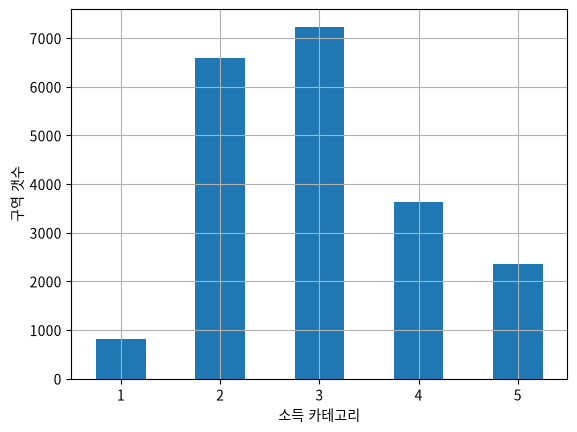

In [12]:
housing_full['income_cat'] = pd.cut(housing_full['median_income'],
                                    bins=[0.0, 1.5, 3.0, 4.5, 6.0, np.inf],
                                    labels=[1,2,3,4,5])

cat_counts = housing_full['income_cat'].value_counts().sort_index()

cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel('소득 카테고리')
plt.ylabel('구역 갯수')

plt.show()

#### `sklearn.model_selection`의 분할기(splitter)

- 분할기
    - 훈련셋과 테스트셋으로 분할하는 방법들
    - 모든 분할기엔 각각에 대한 반복자를 반환하는 `split()` O
    - `split()` : 분할한 데이터셋의 인덱스를 반환 (데이터셋 자체가 X)

In [13]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []

for train_idx, test_idx in splitter.split(housing_full, housing_full['income_cat']) :
    strat_train_set_n = housing_full.iloc[train_idx]
    strat_test_set_n = housing_full.iloc[test_idx]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

# 첫 분할 사용
strat_train_set, strat_test_set = strat_splits[0]

In [14]:
# 계층적 샘플링은 자주 사용된다 -> 1개의 분할 필요시 train_test_split()과 stratify 파라미터를 함께 사용 

strat_train_set, strat_test_set = train_test_split(
    housing_full, test_size=0.2, stratify=housing_full['income_cat'], random_state=42
)

# 테스트셋에서 소득 카테고리의 비율
print(strat_test_set['income_cat'].value_counts() / len(strat_test_set))
print('=' * 30)

# 전체 데셋에서 소득 카테고리 비율
print(housing_full['income_cat'].value_counts() / len(housing_full))
print('=' * 30)

# (참고) 일반 랜덤 샘플링에서의 비율은 전체 데셋 비율과 다르다

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64
income_cat
3    0.350581
2    0.318847
4    0.176308
5    0.114438
1    0.039826
Name: count, dtype: float64


In [15]:
# income_cat feat. 을 사용하지 않으므로 삭제

if ('income_cat' in strat_train_set) or ('income_cat' in strat_test_set) :
    for _set in (strat_train_set, strat_test_set) : 
        _set.drop('income_cat', axis=1, inplace=True)

for _set in [strat_train_set, strat_test_set] : 
    _result = 'income_cat' in _set
    print(_result)
    

False
False


/tmp/ipykernel_37930/2978694026.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  _set.drop('income_cat', axis=1, inplace=True)


- 테스트셋 생성의 중요성 : 실제 ML 프로젝트에서 매우 중요 -> 교차 검증에서 아이디어를 활용

## 2.4 데이터 이해를 돕는 탐색과 시각화

### 2.4.1 지리적 데이터 시각화하기

- 주택 데셋엔 지리 정보(위도/경도) O -> 산점도로 시각화해보기

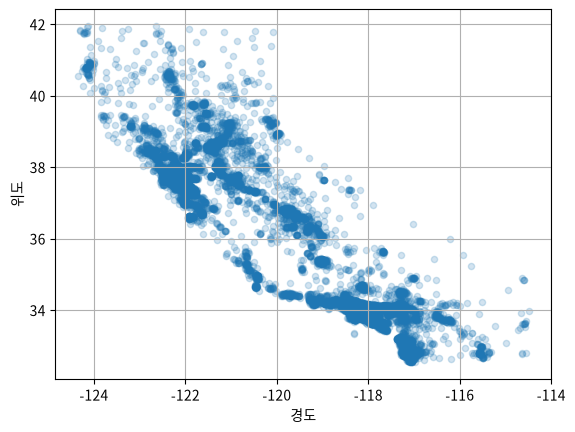

In [16]:
# 원본 데이터 복사
housing = strat_train_set.copy()

# 지리 정보 시각화
housing.plot(kind='scatter', x='longitude', y='latitude', grid=True, alpha=0.2) # alpha : 불투명도
plt.xlabel('경도')
plt.ylabel('위도')

plt.show()

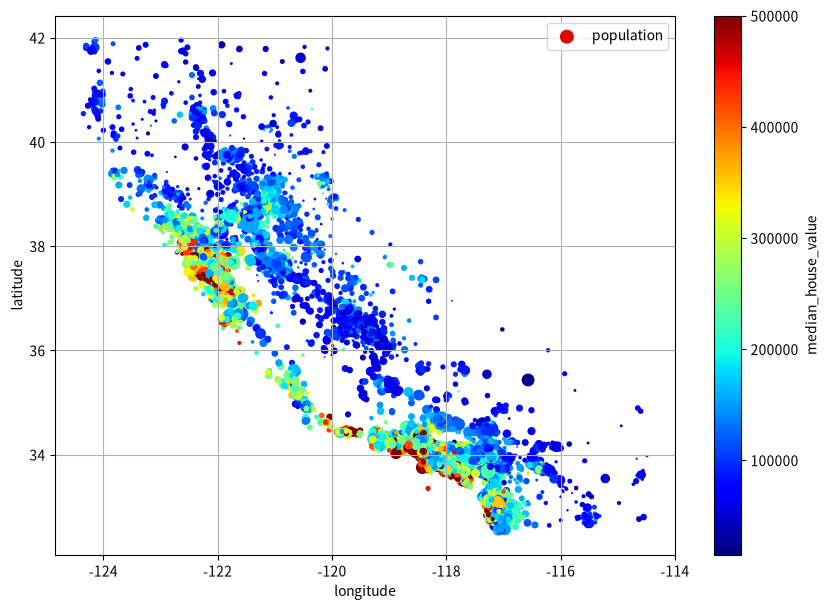

In [17]:
# 주택가격을 반영한 지리 산점도
# 영어 원서 기준 원저자 깃허브 2장 참고

housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
            s=housing["population"] / 100, label="population",
            c="median_house_value", cmap="jet", colorbar=True,
            legend=True, sharex=False, figsize=(10, 7))

plt.show()

- 인사이트
    - 주택 가격은 지역 및 인구 밀도와 관련성이 높다
    - 군집 알고리즘 -> 주요 클러스터들을 찾고 거기까지의 거리를 재는 특성 추가 가능?

### 2.4.2 상관관계 조사하기

- 표준상관계수(피어슨 상관계수 조사 O)
    - 범위 : -1~1
        - -1 일수록 반비례 (음의 상관계수)
        - 0 에 가까울수록 서로 독립적
        - 1에 가까울수록 비례 (양의 상관계수)

- 상관행렬 코드 : `corr_mat = df_name.corr(numeric_only=True)`
    - 특정 feat의 상관계수들 표로 출력 : `corr_mat['col_name'].sort_value(ascending=False)`

- 판다스 `scatter_matrix`를 통한 시각화

    ```python
    from pandas.plotting import scatter_matrix
    attributes = ['median_house_value','median_income','total_rooms','housing_median_age']
    scatter_matrix(housing[attributes], figsize=(12,8))
    plt.show()
    ```
    - 수치형 feat 수 n개 -> $n^2$개의 칸 -> 따라서 서로 높은 상관성이 있는 것 부터 조사
    - 대각선 : (자기자신과의 상관성)=1 이므로 그 대신 히스토그램 출력

In [24]:
corr_matrix = housing.corr(numeric_only=True)

corr_matrix['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

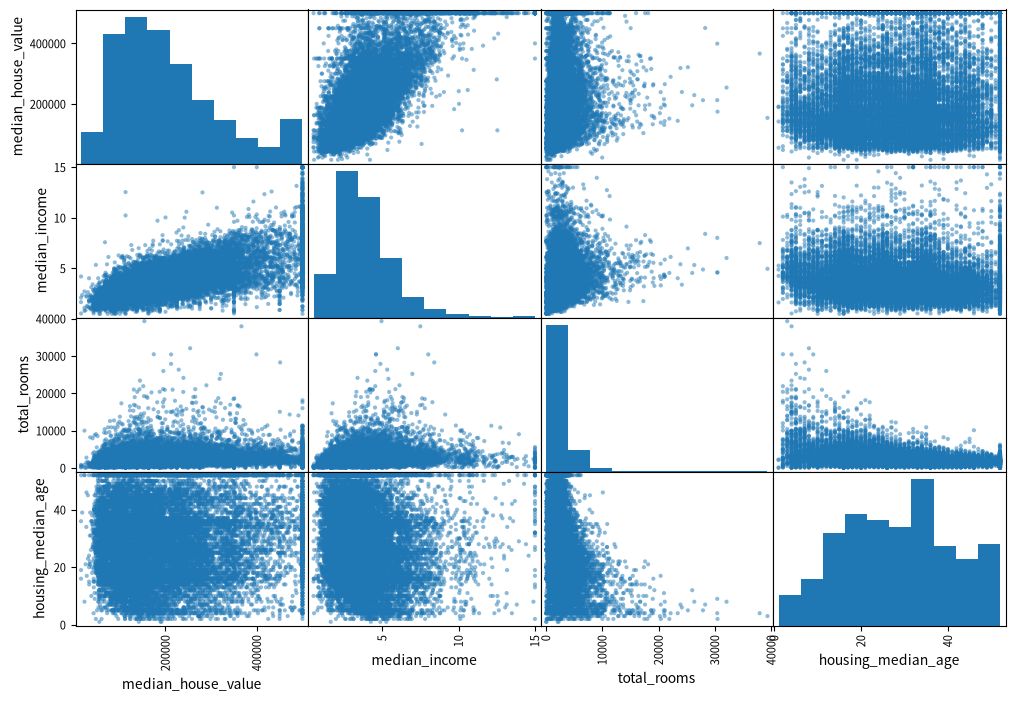

In [ ]:
from pandas.plotting import scatter_matrix

attributes = [
    'median_house_value',
    'median_income',
    'total_rooms',
    'housing_median_age'
]

scatter_matrix(housing[attributes], figsize=(12,8))

plt.show()

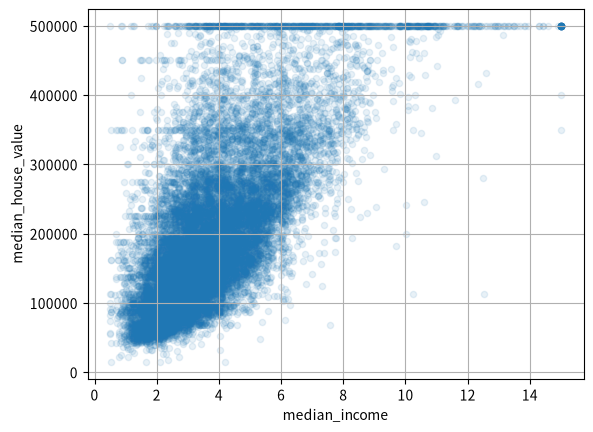

In [ ]:
# 'median_income', 'median_house_value'간 관계에 더 집중

housing.plot(kind='scatter', x='median_income', y='median_house_value', alpha=0.1, grid=True)
plt.show()

- (예제) 중위소득과 중위주택가격간 관계 특징
    1) 상관관계 매우 강함
    2) 주택가격 범위의 최댓값인 50만달러에 수평선 관측
        - 45만, 25만, 28만 달러에서도 수평선 O?
        - 수평선 형태를 학습하지 않도록 해당 구역 제거 가능

- 상관계수 유의점
    - 선형적인 상관관계만 측정 O : 패턴이 있지만 비선형적인 경우는 측정 X -> 즉, (corr$\downarrow$ -> 서로 독립)은 항상 성립 X

### 2.4.3 특성 조합으로 실험하기

- 데이터 주입 전에 변수간 조합을 해보고 적용 가능
    - ex) 방 갯수, 침실 수 -> 한 가구당 방 개수, 침실 수 로 변형 가능
    - 공선성(collinearity) : 새 proxy 변수 만들 때 기존 feat과 너무 큰 corr을 만들지 X도록 주의
        - 특히 기존 feat의 단순 가중합으로 새로 만드는건 X

- EDA 과정이 완벽하지 않아도 빠르게 인사이트 얻고 프로토타입 모델 구축후 다시 EDA가 합리적

## 2.5 머신러닝 알고리즘을 위한 데이터 준비

- 데이터 준비 자동화의 필요성
    1) 모든 데셋에 대해 손쉬운 변환 (새 데셋에 대한 재사용 O)
    2) 다른 프젝에서도 재사용 O 변환 라이브러리 구축 O
    3) 실제 시스템에서 알고리즘에 세 데이터 주입 전 변환 자동 가능
    4) 여러 변환 쉽게 O, 조합 실험 OK

### 2.5.1 데이터 정제

- 대부분 ML 알고리즘 -> 누락 feat X
- 결측치 처리법
    1) 해당 샘플 삭제 : `dropna()`
    2) 해당 feat 삭제 : `drop()`
    3) 대체(imputation) : `fillna()`, `SimpleImputer`
        - 결측치 -> 다른 값(0, 평균, 최빈값 등) 
        - `SimpleImputer` 클래스 : 각 feat. 들의 중위값 저장, 여러 데셋의 결측치도 대체 O
            - `.fit()` : 데셋에 적용
            - `statistics_` : 객체 내 속성. 클래스로 생성된 객체가 각 feat의 중위값을 계산해 해당 속성에 저장
                - 실제 서비스시 어떤 값이 누락될 지 알 수 X -> 모든 속성에 imputer 적용 OK
            - `SimpleImputer(straegy=...)` : ='median', ='mean', ='most_fequent', (='constant', fill_value=...) 가능
        - `sklearn.impute`의 다른 수치형 데이터 대체 클래스
            - `KNNImputer` : k-means 의 평균, 거리 -> 모든 feat에 대해
            - `IterativeImputer` : feat마다 회귀모형 훈련 -> 다른 feat들을 기반으로 해당 결측치 예측 -> 업데이트된 데이터 기반 모델 재훈련 -> 재예측 -> ... -> 몇번 반복해서 모델과 결측치를 향상

#### 사이킷런 설계 철학 및 API
- 일관성 : $\forall$ 객체, 일관 $\cap$ 단순한 인터페이스
    - imputer : (데셋 -> 모델 param 예측) 객체
        - 추정: fit()이 수행
        - 한 param -> 한 데셋에만 전달 ; 추정에 필요한 다른 param? -> 모두 hyparam으로 간주, 인스턴스 변수로 저장
    - transformer : 예측을 수행하는 추정기 (LinearRegression 등)
        - predict() : 데셋 -> 예측 수행
        - score() : 테스트셋 -정 예측의 점수 반환
- 검사 가능 : 모든 추정기에 대해,
    - hyparam. : public 인스턴스 변수로 접근 O
    - 모델 param. : 접미사 '_'를 통해 pub. ins. 변수로 접근 O
- 클래스 남용 방지 : 데셋 -> 넘파이 배열, SciPy sparse mat.로 표현 ; hyparam. -> 문자열, 숫자
- 조합성 : 기존 구성요소 최대한 재사용 ; 여러 변환기 합쳐 pipeline 추정기 OK
- 합리적인 기본값 : 대부분의 매개변수에 적절한 값 지정

In [ ]:
# 훈련셋 복원 및 X, y 분리
# drop() : 데이터 복사본 반환, 기존 영향 X

housing = strat_test_set.drop('median_house_value', axis=1)
housing_labels = strat_train_set['median_house_value'].copy()

### 2.5.2 텍스트와 범주형 특성 다루기

- 대부분 ML 알고리즘 -> 수치형을 다루므로, 범주형 -> 수치형 으로 변환 필요 O

#### 순서 O 범주형 : `OrdianalEncoder`
- 카테고리의 텍스트 -> 숫자 로 변환 
- `categories_` : ins. 변수, 카테고리 리스트 확인 O
    - 범주형 feat. 마다 1D 카테고리 배열을 담은 리스트 반환
        - ex) `[array(['aaa','bbb', ... ]), array([...]), ...]`
- 문제점 : 각 카테고리를 숫자로 변환시,
    - 순서 O 카테 : 문제 X
        - ([excellent, good, average, bad] 등)
    - 순서 X 카테: 문제 O(비슷함이 순서랑 상관 없음)
        - ([seoul, busan, guangzhou, incheon] 등) 
        - 해결책 : one hot encoding (새로 만들어지는 binary 변수 -> dummy 변수라고도 함)

#### 순서 X 범주형 : one hot encoding의 방법들
1) 사이킷런 `OneHotEncoder` 클래스
    - 희소행렬 : 대부분 값이 0, 기본 

2) 판다스 `get_dummies()` : cat-(OHE)->binary 특성;

#### 범주형 feat의 카테고리가 매우 많을 경들